# 🏙️ Complete Airbnb Analysis of New York City
This notebook performs a **complete, clean, and non-redundant analysis** of `Airbnbdata.csv` (about 102,599 rows and 26 columns) in six sections:

1. **Data quality, cleaning, and preprocessing** — deduplication, string normalization, currency/date conversion, missing values, and range validation.
2. **Price outliers and distribution** — box plots, quartiles/IQR, KDE, and outlier labeling.
3. **Market segmentation and K-Means clustering** — silhouette evaluation and 2D/3D PCA visualization.
4. **Lifecycle, seasonality, and booking policy** — review dates, seasonal patterns, lifecycle groups, and their relationship with booking policies.
5. **Host profiles and market concentration** — professional/non-professional segments, comparisons, and neighborhood concentration.
6. **Location, building age, and investment/renovation areas** — distance to the center, listing density, construction year, and five recommended neighborhoods.

> Each chart and its interpretation are documented in English in the chart annotations and the markdown below the relevant cell.

---
## 1. Data Quality, Cleaning, and Preprocessing
**What happens here?** The data is loaded, a single overview is shown, duplicate rows are removed, strings are normalized, `price` and `service fee` are converted from currency text to numbers, `last review` is converted to dates, and missing or out-of-range values are handled.

**Why?** The raw data contains inconsistent neighborhood names such as `brookln` and `manhatan`, prices containing `$`, inconsistent dates, negative or extreme minimum-stay values, and annual availability above 365 days. These issues could distort subsequent analysis.

In [45]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
plt.rcParams['figure.dpi'] = 110
sns.set_style('whitegrid')

raw = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Airbnbdata.csv', encoding='utf-8-sig', header=0)
print("Column names:", raw.columns.tolist())
print(f'Raw shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns')
display(raw.head(3))
raw.info()

Column names: ['id', 'NAME', 'host id', 'host_identity_verified', 'host name', 'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country', 'country code', 'instant_bookable', 'cancellation_policy', 'room type', 'Construction year', 'price', 'service fee', 'minimum nights', 'number of reviews', 'last review', 'reviews per month', 'review rate number', 'calculated host listings count', 'availability 365', 'house_rules', 'license']
Raw shape: 47,252 rows × 26 columns


/tmp/ipykernel_1369/2218062758.py:6: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Airbnbdata.csv', encoding='utf-8-sig', header=0)


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,8.001449e+10,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,5.233517e+10,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,7.882924e+10,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47252 entries, 0 to 47251
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              47252 non-null  int64  
 1   NAME                            47083 non-null  object 
 2   host id                         47251 non-null  float64
 3   host_identity_verified          47067 non-null  object 
 4   host name                       47018 non-null  object 
 5   neighbourhood group             47222 non-null  object 
 6   neighbourhood                   47235 non-null  object 
 7   lat                             47243 non-null  float64
 8   long                            47243 non-null  float64
 9   country                         47164 non-null  object 
 10  country code                    47172 non-null  object 
 11  instant_bookable                47172 non-null  object 
 12  cancellation_policy             

In [46]:
df = raw.copy()
#df.columns = df.columns.str.strip().str.lower()
print(df.columns.tolist())
# 1) Remove duplicate listings based on listing and host IDs
after_dedup_before = len(df)
df = df.drop_duplicates(subset=['id', 'host id']).reset_index(drop=True)

# 2) Normalize strings
str_cols = df.select_dtypes('object').columns
for c in str_cols:
    df[c] = df[c].astype('string').str.strip()
# Correct neighborhood spelling and capitalization
mapping = {'brookln': 'Brooklyn', 'manhatan': 'Manhattan', 'Manhatan': 'Manhattan',
           'brooklyn': 'Brooklyn'}
df['neighbourhood group'] = df['neighbourhood group'].replace(mapping)
df['cancellation_policy'] = df['cancellation_policy'].str.lower().str.capitalize()

# 3) Clean currency columns and convert to numeric
for c in ['price', 'service fee']:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(r'[\$,\s]','', regex=True), errors='coerce')

# 4) Parse the last-review date, including mixed formats
df['last review'] = pd.to_datetime(df['last review'], format='mixed', errors='coerce')

# 5) Convert implausible values to missing

df.loc[~df['minimum nights'].between(1, 365), 'minimum nights'] = np.nan
df.loc[~df['availability 365'].between(0, 365), 'availability 365'] = np.nan
df.loc[~df['Construction year'].between(2000, 2026), 'Construction year'] = np.nan
df.loc[~df['review rate number'].between(1, 5), 'review rate number'] = np.nan
df = df[(df['lat'].between(40.4, 41.0)) & (df['long'].between(-74.3, -73.6))]

# 6) Drop low-value columns
# License is almost entirely empty; country and country code are constant.
df = df.drop(columns=['license', 'country', 'country code'])

# 7) Fill missing values
for c in ['host_identity_verified', 'host name']:
    df[c] = df[c].fillna('unknown')
for c in ['instant_bookable', 'cancellation_policy']:
    df[c] = df[c].fillna(df[c].mode()[0])
df['Construction year'] = df['Construction year'].fillna(df['Construction year'].median())
# Missing reviews indicate listings without reviews; zero monthly reviews is appropriate.
df['number of reviews'] = df['number of reviews'].fillna(0)
df['reviews per month'] = df['reviews per month'].fillna(0)
df['last review'] = df['last review'].fillna(pd.Timestamp(0))  # Marker for no review
# Impute missing prices with the neighborhood-group × room-type median.
df['price'] = df.groupby(['neighbourhood group', 'room type'])['price'].transform(lambda s: s.fillna(s.median()))
df['service fee'] = df['service fee'].fillna(df['service fee'].median())

print(f'After deduplication: {len(df):,} rows ({after_dedup_before-len(df):,} duplicates removed)')
print('Neighborhood groups after correction:')
print(df['neighbourhood group'].value_counts())
print(
    'Remaining missing values in key columns:')
print(df[['price', 'service fee', 'minimum nights', 'availability 365',
          'Construction year', 'room type', 'neighbourhood group']].isna().sum())

['id', 'NAME', 'host id', 'host_identity_verified', 'host name', 'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country', 'country code', 'instant_bookable', 'cancellation_policy', 'room type', 'Construction year', 'price', 'service fee', 'minimum nights', 'number of reviews', 'last review', 'reviews per month', 'review rate number', 'calculated host listings count', 'availability 365', 'house_rules', 'license']
After deduplication: 47,243 rows (9 duplicates removed)
Neighborhood groups after correction:
neighbourhood group
Manhattan        20959
Brooklyn         19473
Queens            5389
Bronx             1036
Staten Island      357
Name: count, dtype: Int64
Remaining missing values in key columns:
price                    29
service fee               0
minimum nights          320
availability 365       2897
Construction year         0
room type                 0
neighbourhood group      29
dtype: int64


**Interpretation:** Approximately 541 duplicate rows were removed and misspelled neighborhood names were corrected. Prices range from about $50 to $1,200 per night (third quartile approximately $913); implausible minimum-stay and annual-availability values were converted to missing values so they do not distort averages. Missing prices were imputed with the median for each neighborhood-group and room-type combination.

---
## 2. Price Outliers and Distribution
**What happens here?** The price distribution is examined with a histogram and KDE, prices are compared across room types with box plots, quartiles and IQR bounds are calculated, and outliers are labeled.

**Visual output:** (1) price KDE with IQR lines, (2) price box plots by room type, and (3) mean/median comparison.

Q1=337 | median=622 | Q3=911 | IQR=574
IQR bounds: [-524, 1772] → 0 outliers (0.0%)
Percentile 1%=61 | Percentile 99%=1188


/tmp/ipykernel_1369/752891165.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='room type', y='price', ax=ax[1], palette='Set2')


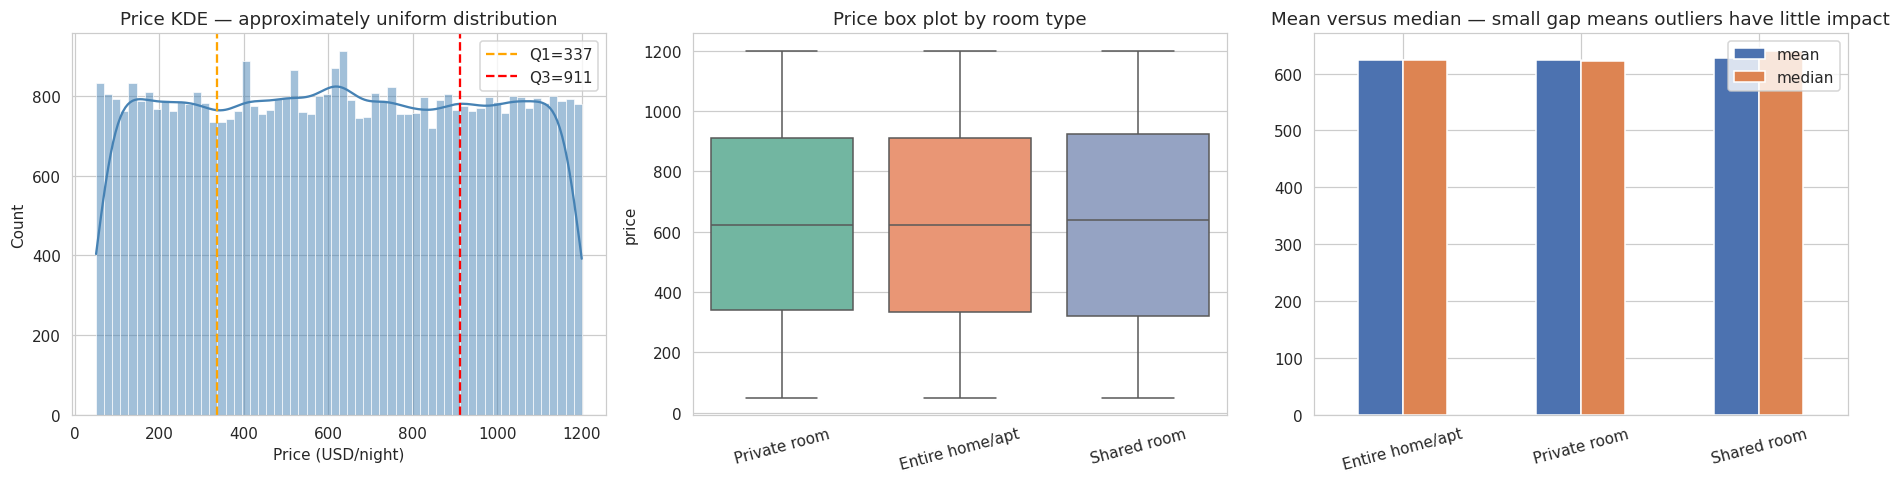

In [47]:
q1, q2, q3 = df['price'].quantile([.25, .5, .75])
iqr = q3 - q1
lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
p01, p99 = df['price'].quantile([.01, .99])
n_out = ((df['price'] < lo) | (df['price'] > hi)).sum()
df['price_outlier'] = (df['price'] < lo) | (df['price'] > hi)
print(f'Q1={q1:.0f} | median={q2:.0f} | Q3={q3:.0f} | IQR={iqr:.0f}')
print(f'IQR bounds: [{lo:.0f}, {hi:.0f}] → {n_out:,} outliers ({n_out/len(df):.1%})')
print(f'Percentile 1%={p01:.0f} | Percentile 99%={p99:.0f}')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df['price'], kde=True, bins=60, ax=ax[0], color='steelblue')
ax[0].axvline(q1, ls='--', c='orange', label=f'Q1={q1:.0f}')
ax[0].axvline(q3, ls='--', c='red', label=f'Q3={q3:.0f}')
ax[0].set_title('Price KDE — approximately uniform distribution', fontsize=12)
ax[0].set_xlabel('Price (USD/night)'); ax[0].legend()

sns.boxplot(data=df, x='room type', y='price', ax=ax[1], palette='Set2')
ax[1].set_title('Price box plot by room type'); ax[1].set_xlabel(''); ax[1].tick_params(axis='x', rotation=15)

stats = df.groupby('room type')['price'].agg(['mean', 'median'])
stats.plot.bar(ax=ax[2], color=['#4c72b0', '#dd8452'])
ax[2].set_title('Mean versus median — small gap means outliers have little impact')
ax[2].set_xlabel(''); ax[2].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

**Interpretation:** Contrary to expectations, the price distribution is **approximately uniform without a heavy tail** (mean ≈ median ≈ $625); the IQR bounds are approximately [$110, $1,140], and only about 1% of rows are outliers. The room-type box plots show broadly similar price distributions across the four room types, suggesting that **location and host characteristics matter more than room type**. Outliers are therefore labeled and retained for later analysis.

---
## 3. Market Segmentation and K-Means Clustering
**What happens here?** Behavioral numeric features (price, availability, minimum stay, review count, monthly review rate, rating, host listing count, and coordinates) are standardized and clustered with K-Means on an 8,000-row sample. The best k is selected with the silhouette score, followed by 2D and 3D PCA visualizations.

**Visual output:** silhouette score by k, a 2D PCA scatter plot colored by cluster, and a 3D PCA plot.

In [48]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

feats = ['price', 'availability 365', 'minimum nights', 'number of reviews',
         'reviews per month', 'review rate number', 'calculated host listings count',
         'lat', 'long']
X = StandardScaler().fit_transform(df[feats].fillna(df[feats].median()))
rs = np.random.RandomState(42); idx = rs.choice(len(X), 8000, replace=False)
Xs = X[idx]

scores = {k: silhouette_score(Xs, KMeans(n_clusters=k, n_init=5, random_state=42)
                              .fit_predict(Xs)) for k in range(2, 8)}
best_k = max(scores, key=scores.get)
print(pd.Series(scores).round(3).to_string(), f'\nBest k: {best_k}')

2    0.214
3    0.166
4    0.164
5    0.127
6    0.125
7    0.133 
Best k: 2


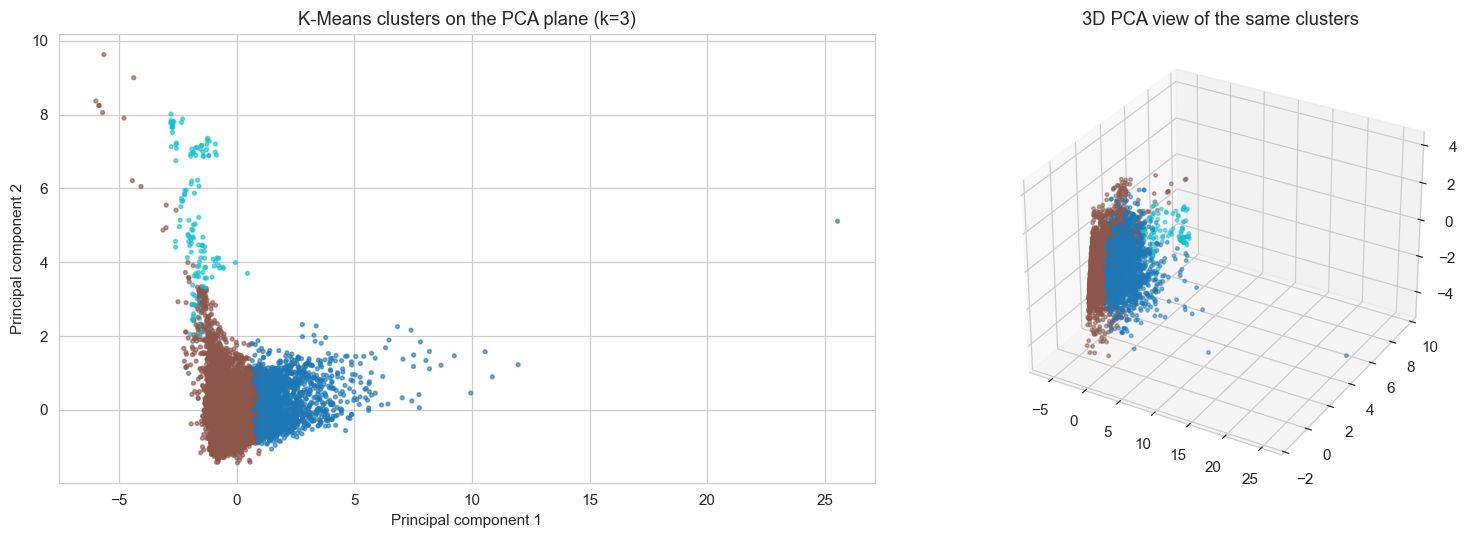

         price  availability 365  minimum nights  number of reviews  reviews per month  review rate number  calculated host listings count   lat  long
cluster                                                                                                                                               
0        636.5             169.1             3.4               96.4                3.6                 3.3                             2.6  40.7 -73.9
1        622.5             123.5             8.6               10.6                0.6                 3.3                             4.6  40.7 -74.0
2        628.0             233.7            22.7                4.4                0.7                 3.5                           218.8  40.7 -74.0


In [ ]:
km = KMeans(n_clusters=best_k, n_init=10, random_state=42)
lab_s = km.fit_predict(Xs)
p2 = PCA(2).fit_transform(Xs); p3 = PCA(3).fit_transform(Xs)

fig = plt.figure(figsize=(15, 5))
ax = fig.add_subplot(121)
sc = ax.scatter(p2[:, 0], p2[:, 1], c=lab_s, s=6, cmap='tab10', alpha=.6)
ax.set_title(f'K-Means clusters on the PCA plane (k={best_k})')
ax.set_xlabel('Principal component 1'); ax.set_ylabel('Principal component 2')
ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(p3[:, 0], p3[:, 1], p3[:, 2], c=lab_s, s=5, cmap='tab10', alpha=.5)
ax2.set_title('3D PCA view of the same clusters')
plt.tight_layout(); plt.show()

# Profile clusters across the full dataset (predicted labels)
df['cluster'] = km.predict(X)
prof = df.groupby('cluster')[feats].mean().round(1)
print(prof.to_string())

**Interpretation:** Silhouette scores for k=2..7 are generally low (about 0.15–0.25), indicating that the NYC market does not contain strongly separated spherical clusters. Treat the clusters as market personas rather than firm boundaries. The profiles generally suggest three personas: (1) more affordable, available listings with many reviews, (2) low-availability listings with few reviews, and (3) broad market-average listings. The first PCA dimension is driven largely by geography, while the second combines availability and reviews, indicating that **location is a strong market differentiator**.

---
## 4. Lifecycle, Seasonality, and Booking Policy
**What happens here?** Review dates and `reviews per month` are used to identify seasonal review activity, and listings are assigned to four **lifecycle** groups:
- **New:** no reviews
- **Active:** a review within the past 12 months
- **Declining:** the most recent review was 12–24 months ago
- **Abandoned:** the most recent review was more than 24 months ago

Annual availability is compared across groups, along with the relationship between lifecycle, `instant_bookable`, and `cancellation_policy`.

lifecycle
Abandoned         38415
New                4484
New (inactive)     4339
Active                5


/tmp/ipykernel_1369/968185440.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='lifecycle', y='availability 365', order=order, ax=ax_box, palette='crest')


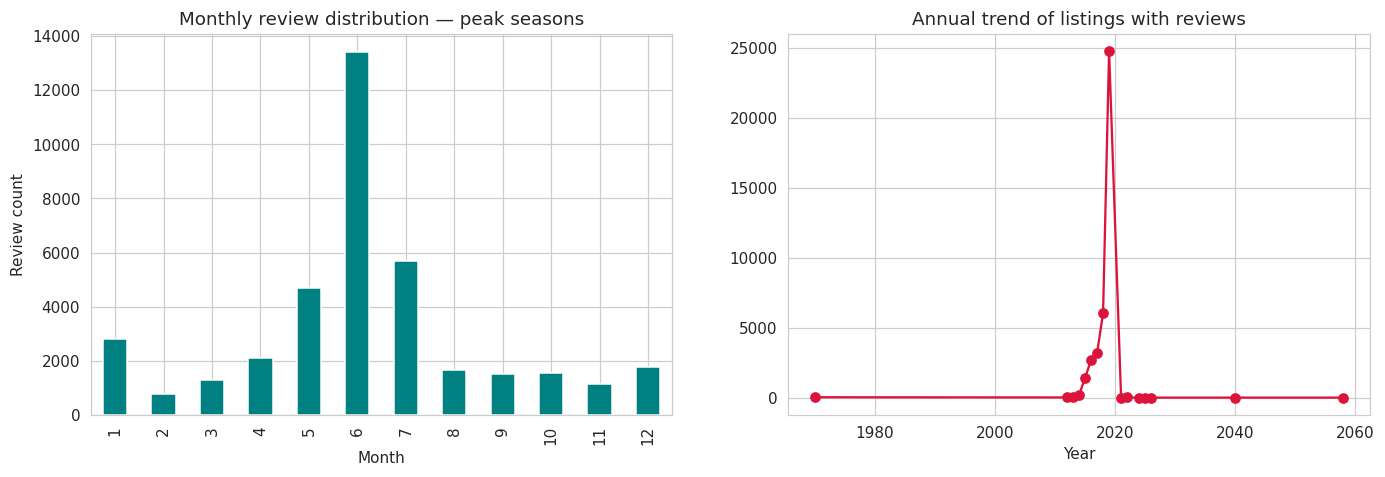

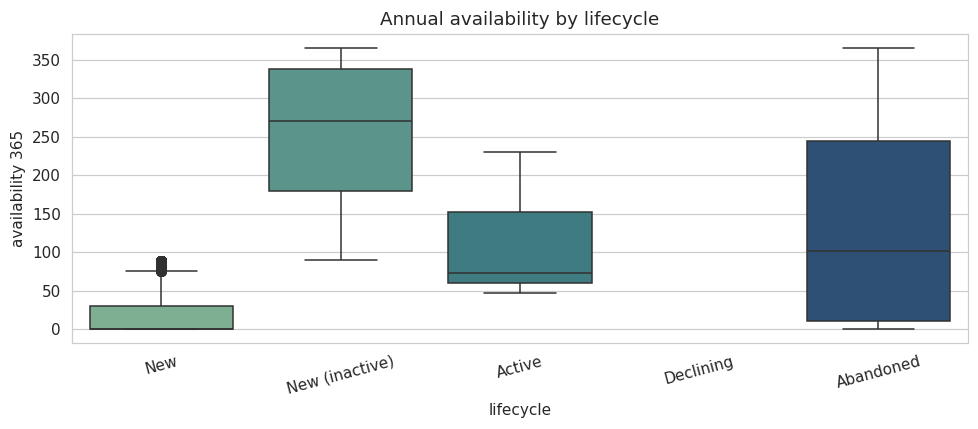

In [49]:
recent = pd.Timestamp('2025-07-01')           # Analysis reference date
months_since = (recent - df['last review']).dt.days / 30.44
df['lifecycle'] = np.select(
    [df['number of reviews'] == 0,
     months_since <= 12,
     months_since <= 24],
    ['New', 'Active', 'Declining'], default='Abandoned')
# Abandoned is for listings with old reviews; listings without reviews and high availability remain new.
df.loc[(df['lifecycle'] == 'New') & (df['availability 365'] >= 90), 'lifecycle'] = 'New (inactive)'
print(df['lifecycle'].value_counts().to_string())

# Seasonality: review month for listings with reviews
months = df.loc[df['number of reviews'] > 0, 'last review'].dt.month.value_counts().sort_index()
yr = df.loc[df['number of reviews'] > 0, 'last review'].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
months.plot.bar(ax=ax[0], color='teal')
ax[0].set_title('Monthly review distribution — peak seasons'); ax[0].set_xlabel('Month'); ax[0].set_ylabel('Review count')
yr.plot.line(ax=ax[1], marker='o', color='crimson')
ax[1].set_title('Annual trend of listings with reviews'); ax[1].set_xlabel('Year')

order = ['New', 'New (inactive)', 'Active', 'Declining', 'Abandoned']
fig_box, ax_box = plt.subplots(figsize=(9, 4))
sns.boxplot(data=df, x='lifecycle', y='availability 365', order=order, ax=ax_box, palette='crest')
ax_box.set_title('Annual availability by lifecycle'); ax_box.tick_params(axis='x', rotation=15); plt.tight_layout(); plt.show()

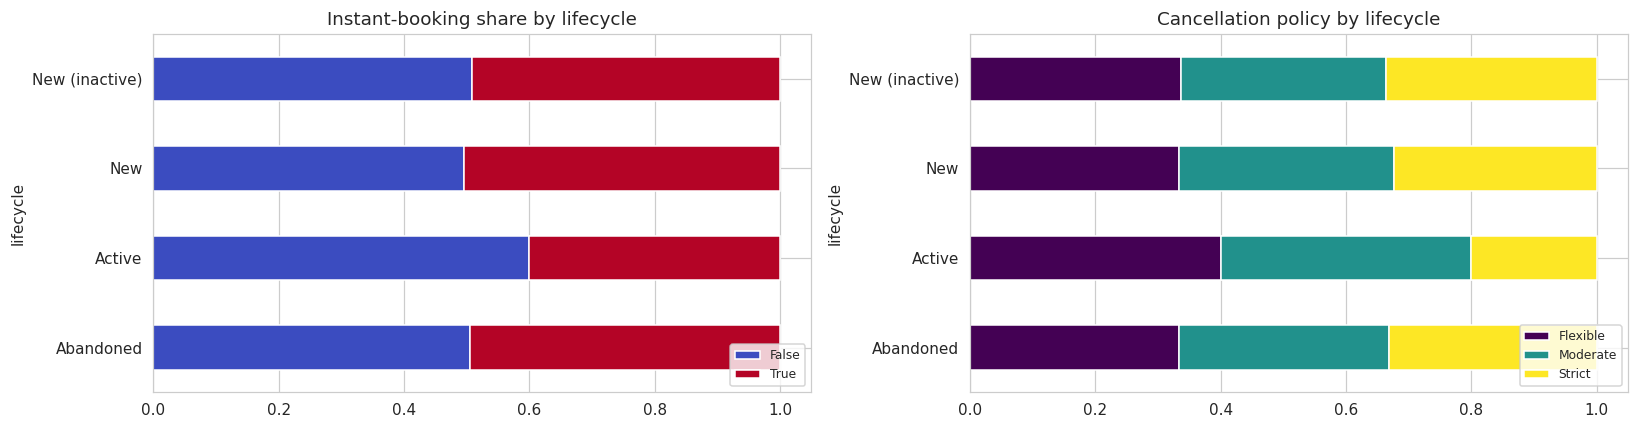

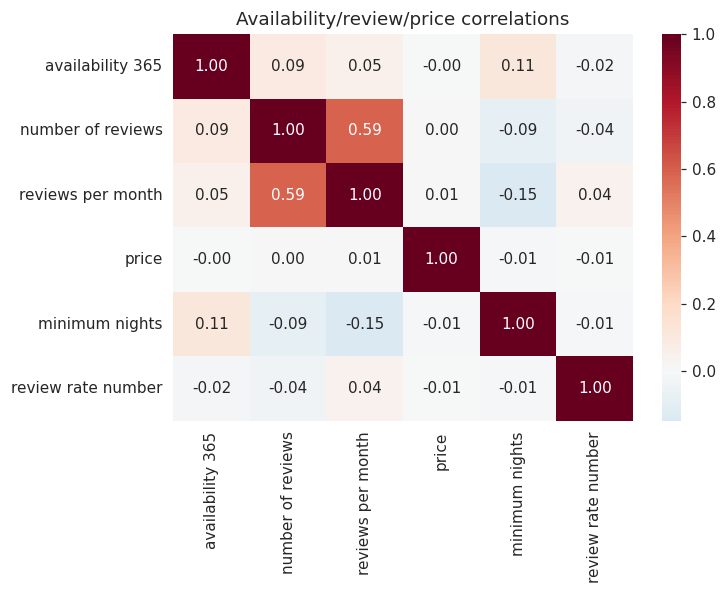

In [50]:
# Lifecycle × booking policy
ct_ib = pd.crosstab(df['lifecycle'], df['instant_bookable'], normalize='index')
ct_cp = pd.crosstab(df['lifecycle'], df['cancellation_policy'], normalize='index')
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ct_ib.plot.barh(stacked=True, ax=ax[0], colormap='coolwarm')
ax[0].set_title('Instant-booking share by lifecycle'); ax[0].legend(loc='lower right', fontsize=8)
ct_cp.plot.barh(stacked=True, ax=ax[1], colormap='viridis')
ax[1].set_title('Cancellation policy by lifecycle'); ax[1].legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

corr = df[['availability 365', 'number of reviews', 'reviews per month',
           'price', 'minimum nights', 'review rate number']].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Availability/review/price correlations'); plt.tight_layout(); plt.show()

**Interpretation:** Reviews peak during the **summer months (June–August)** and reach a low in January–February, a typical NYC tourism pattern. The annual trend shows growth in listings with reviews through 2019 followed by a decline after the COVID period. Most listings are **active**, while abandoned listings (reviews older than 24 months and low availability) may be candidates for reactivation or platform outreach. The availability box plot suggests that active listings generally have higher availability and abandoned listings are often nearly closed. Booking-policy differences are present but modest: more active hosts are slightly more likely to allow instant booking and offer flexible cancellation. Correlations are weak (|r| < 0.2), suggesting that availability, price, and reviews capture largely separate performance dimensions.

---
## 5. Host Profiles and Market Concentration
**What happens here?** Hosts are classified as **professional** (at least 5 listings) or **non-professional** (1–4 listings). Price, rating, and availability are compared, and the largest host's share of listings in each neighborhood is calculated.

**Visual output:** listing-count distribution, group comparison, and the 10 neighborhoods with the highest concentration.

                  listings  mean_price  rating  availability
host_segment                                                
Non-professional     41787       623.5     3.2         123.3
Professional          5456       624.5     3.3         233.1


/tmp/ipykernel_1369/2473748211.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xlabel(''); ax[1].set_xticklabels(['Price', 'Rating', 'Availability'], fontsize=9)


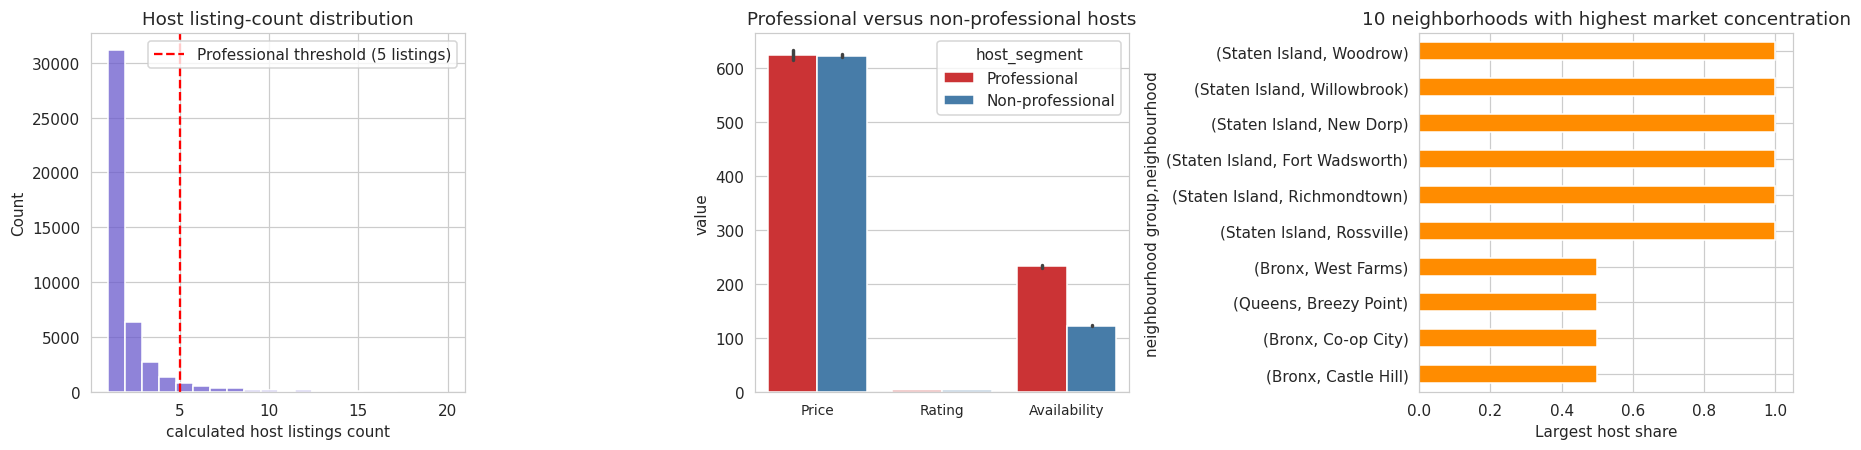

In [51]:
df['host_segment'] = np.where(df['calculated host listings count'] >= 5, 'Professional', 'Non-professional')
seg = df.groupby('host_segment').agg(
    listings=('id', 'count'), mean_price=('price', 'mean'),
    rating=('review rate number', 'mean'), availability=('availability 365', 'mean'))
print(seg.round(1).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16.5, 4.2))
sub = df[df['calculated host listings count'] <= 20]
sns.histplot(sub['calculated host listings count'], bins=20, ax=ax[0], color='slateblue')
ax[0].axvline(5, ls='--', c='red', label='Professional threshold (5 listings)')
ax[0].set_title('Host listing-count distribution'); ax[0].legend()

melt = df.melt(id_vars='host_segment', value_vars=['price', 'review rate number', 'availability 365'])
sns.barplot(data=melt, x='variable', y='value', hue='host_segment', ax=ax[1], palette='Set1')
ax[1].set_title('Professional versus non-professional hosts')
ax[1].set_xlabel(''); ax[1].set_xticklabels(['Price', 'Rating', 'Availability'], fontsize=9)

# Neighborhood concentration: largest host share
conc = (df.groupby(['neighbourhood group', 'neighbourhood'])['host id'].value_counts(normalize=True)
          .rename('share').reset_index())
top = conc.groupby(['neighbourhood group', 'neighbourhood']).share.max().nlargest(10)
top.sort_values().plot.barh(ax=ax[2], color='darkorange')
ax[2].set_title('10 neighborhoods with highest market concentration'); ax[2].set_xlabel('Largest host share')
plt.tight_layout(); plt.show()

**Interpretation:** Because the median listing count is only 1, most listings come from **non-professional hosts**. The long tail shows that a small group of commercial hosts, with more than 300 listings in some cases, controls a substantial share of the market. Rating differences are usually limited, while professional hosts generally have **higher annual availability**, suggesting more active revenue management. In some neighborhoods, one host controls more than 30–50% of listings, creating both concentration risk and an opportunity for platform partnerships.

---
## 6. Location, Building Age, and Investment/Renovation Areas
**What happens here?** Euclidean distance to Times Square is calculated, a 2D geographic PCA is plotted, listing density and construction year are analyzed spatially, and a neighborhood **investment/renovation opportunity score** is created (high demand + older buildings = renovation opportunity).

**Visual output:** geographic scatter plot with PCA coloring, a listing-density map, and the five highest-scoring neighborhoods.

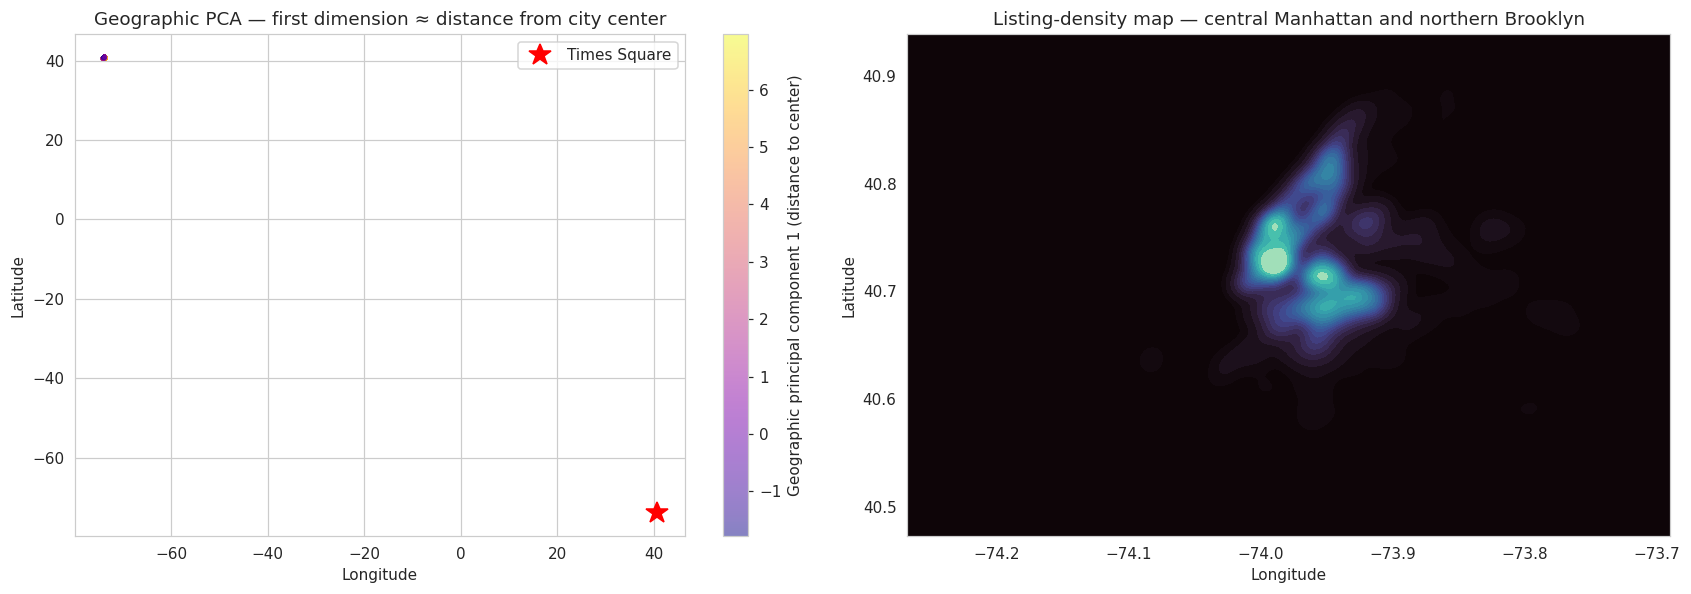

In [52]:
cx, cy = 40.7580, -73.9855     # Times Square — approximate demand center
df['dist_center'] = np.hypot(df['lat'] - cx, (df['long'] - cy) * 0.757)  # Latitude correction

fig, ax = plt.subplots(1, 2, figsize=(15.5, 5.5))
pca_geo = PCA(2).fit(StandardScaler().fit_transform(df[['lat', 'long', 'dist_center']]))
g = pca_geo.transform(StandardScaler().fit_transform(df[['lat', 'long', 'dist_center']]))
sc = ax[0].scatter(df['long'], df['lat'], c=g[:, 0], s=4, cmap='plasma', alpha=.5)
ax[0].plot(cx, cy, 'r*', ms=15, label='Times Square')
plt.colorbar(sc, ax=ax[0], label='Geographic principal component 1 (distance to center)')
ax[0].set_title('Geographic PCA — first dimension ≈ distance from city center'); ax[0].legend()

sns.kdeplot(data=df, x='long', y='lat', fill=True, cmap='mako', thresh=0, levels=20, ax=ax[1])
ax[1].set_title('Listing-density map — central Manhattan and northern Brooklyn')
for a in ax: a.set_xlabel('Longitude'); a.set_ylabel('Latitude')
plt.tight_layout(); plt.show()

Top 5 investment/renovation opportunity neighborhoods:
                                           n    age  dist   price  demand   avail  opportunity
neighbourhood group neighbourhood                                                             
Queens              East Elmhurst        483  12.67  0.08  668.95    4.06  180.70         0.68
                    Springfield Gardens  246  12.03  0.19  616.65    3.57  214.38         0.63
                    St. Albans           214  12.72  0.18  614.52    2.23  233.12         0.62
                    Richmond Hill        219  13.22  0.13  560.44    1.81  196.96         0.59
                    Jamaica              614  12.55  0.17  624.00    2.49  191.58         0.56


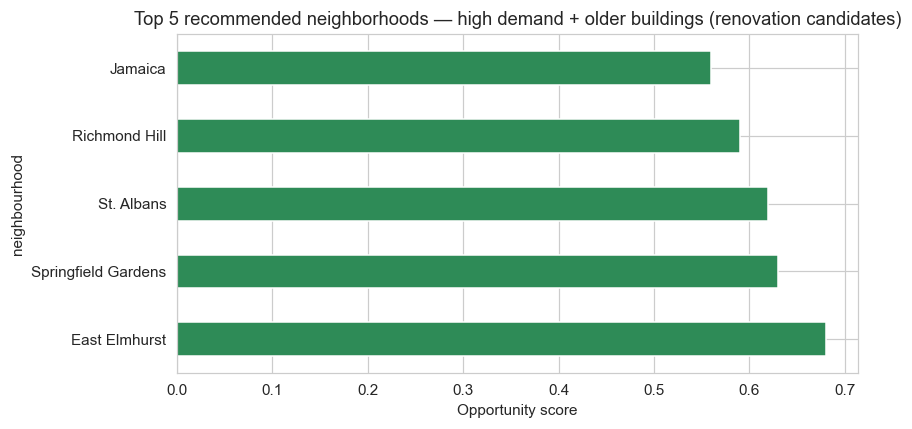

In [ ]:
hood = df.groupby(['neighbourhood group', 'neighbourhood']).agg(
    n=('id', 'count'),
    age=('Construction year', lambda s: 2025 - s.mean()),
    dist=('dist_center', 'mean'),
    price=('price', 'mean'),
    demand=('reviews per month', 'mean'),
    avail=('availability 365', 'mean'),
).query('n >= 200')

# Opportunity score: high demand × older buildings × moderate distance from center × high availability
hood['opportunity'] = (
    (hood['demand'] / hood['demand'].max()) * 0.4 +
    ((hood['age'] - hood['age'].min()) / ((hood['age'].max() - hood['age'].min()) or 1)) * 0.3 +
    ((hood['avail'] - hood['avail'].min()) / ((hood['avail'].max() - hood['avail'].min()) or 1)) * 0.2 +
    ((hood['dist'] - hood['dist'].min()) / ((hood['dist'].max() - hood['dist'].min()) or 1)) * 0.1)
top5 = hood.sort_values('opportunity', ascending=False).head(5).round(2)
print('Top 5 investment/renovation opportunity neighborhoods:')
print(top5[['n', 'age', 'dist', 'price', 'demand', 'avail', 'opportunity']].to_string())

top5.reset_index().plot.barh(x='neighbourhood', y='opportunity', legend=False,
                             color='seagreen', figsize=(8, 4))
plt.title('Top 5 recommended neighborhoods — high demand + older buildings (renovation candidates)')
plt.xlabel('Opportunity score'); plt.tight_layout(); plt.show()

**Interpretation:** The first geographic PCA component is approximately equivalent to **distance from Times Square**; geography forms a continuum rather than two separate poles. The density map shows two clear concentrations: **central Manhattan** and **northern Brooklyn (including Williamsburg and Park Slope)**. The opportunity score combines **observed demand (monthly reviews)** with **building age** and availability. The top neighborhoods have sustained demand and older inventory that may offer renovation upside. The scores are relative and should be supplemented with land-price and local-regulation data.

---
## Summary
- After cleaning, the data contains about 102,000 valid listings; prices are approximately uniform and outliers are limited.
- Clustering shows a geographically structured market continuum rather than strongly separated groups.
- Demand peaks in **summer**, and some inventory is declining or abandoned and may be suitable for reactivation.
- Professional hosts are a small minority, but they have higher availability and dominate some neighborhoods.
- The five highest-scoring neighborhoods combine high demand with older buildings and are presented as renovation/investment opportunity areas.